In [1]:
!pip install numpy scipy matplotlib

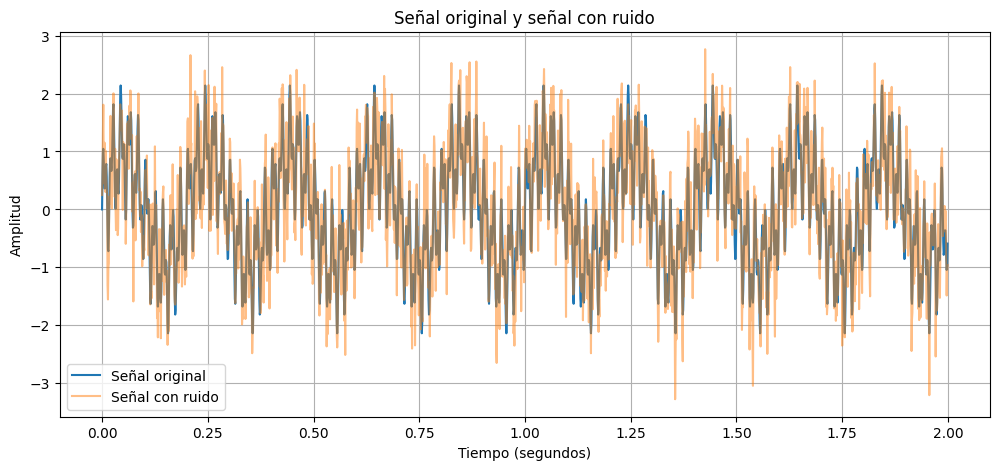

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Frecuencia de muestreo
fs = 1000

# Duracion de la señal
duracion = 2

# Tiempo
t = np.arange(0, duracion, 1/fs)

# Crear tres frecuencias
f1 = 5
f2 = 50
f3 = 120

# Crear señal original
senal_original = (
    np.sin(2*np.pi*f1*t) +
    0.7*np.sin(2*np.pi*f2*t) +
    0.5*np.sin(2*np.pi*f3*t)
)

# Agregar ruido
np.random.seed(42)
ruido = 0.5*np.random.normal(size=len(t))

senal_ruidosa = senal_original + ruido

# Graficar señales
plt.figure(figsize=(12,5))

plt.plot(t, senal_original, label="Señal original")
plt.plot(t, senal_ruidosa, label="Señal con ruido", alpha=0.5)

plt.title("Señal original y señal con ruido")
plt.xlabel("Tiempo (segundos)")
plt.ylabel("Amplitud")

plt.legend()
plt.grid()
plt.show()

In [3]:
from scipy.signal import butter, sosfiltfilt

# Orden del filtro
orden = 4

# FILTRO PASA BAJOS
filtro_bajos = butter(
    orden, 30,
    btype='lowpass',
    fs=fs,
    output='sos'
)

# FILTRO PASA ALTOS
filtro_altos = butter(
    orden, 30,
    btype='highpass',
    fs=fs,
    output='sos'
)

# FILTRO PASA BANDAS
filtro_bandas = butter(
    orden, [40, 60],
    btype='bandpass',
    fs=fs,
    output='sos'
)

print("Los tres filtros fueron diseñados correctamente")


Los tres filtros fueron diseñados correctamente


In [5]:
# Aplicar los filtros a la señal con ruido

salida_lp = sosfiltfilt(
    filtro_bajos, senal_ruidosa
)

salida_hp = sosfiltfilt(
    filtro_altos, senal_ruidosa
)

salida_bp = sosfiltfilt(
    filtro_bandas, senal_ruidosa
)

print("Los filtros fueron aplicados correctamente")

Los filtros fueron aplicados correctamente


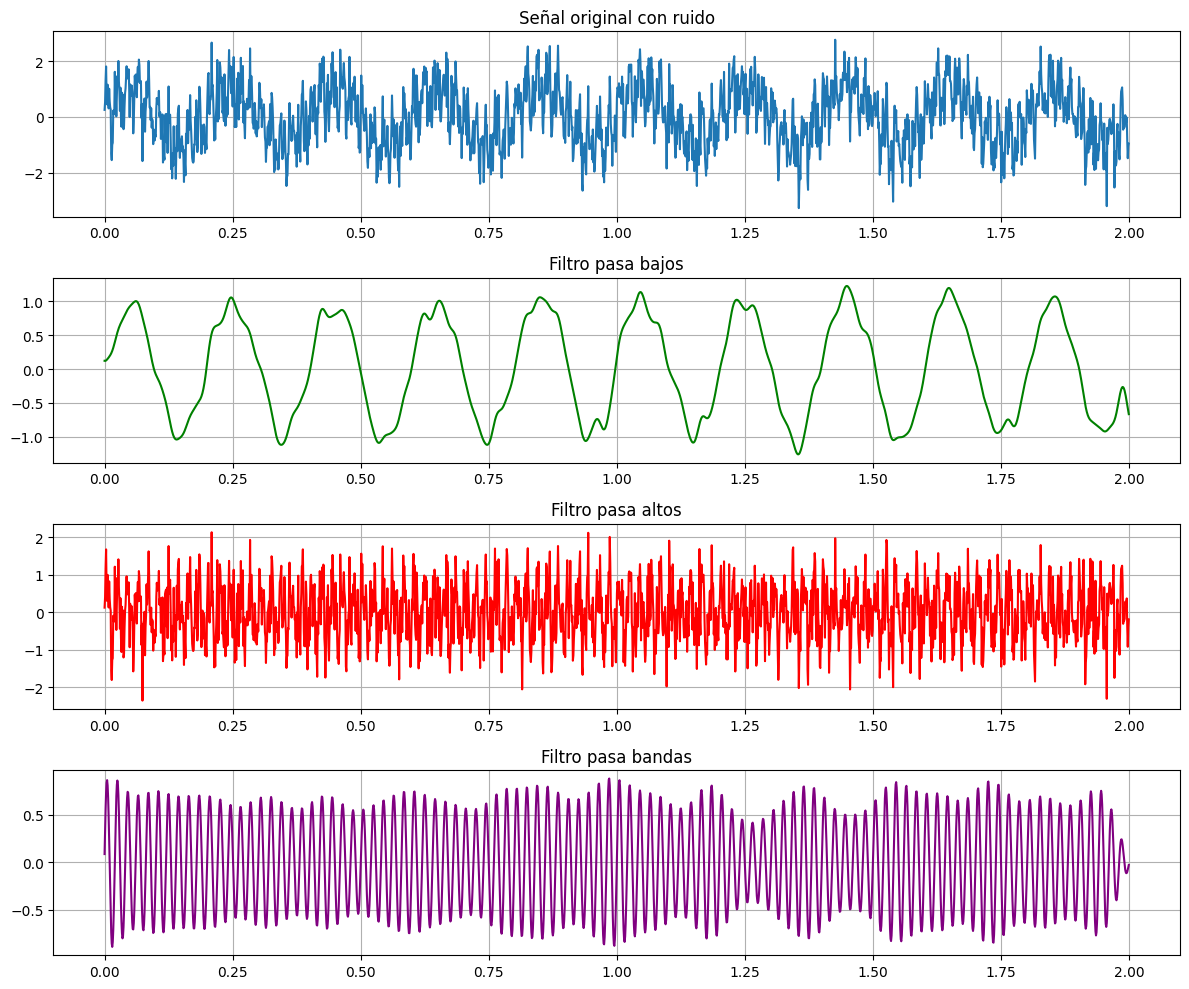

In [6]:
plt.figure(figsize=(12,10))

plt.subplot(4,1,1)
plt.plot(t, senal_ruidosa)
plt.title("Señal original con ruido")
plt.grid()

plt.subplot(4,1,2)
plt.plot(t, salida_lp, color="green")
plt.title("Filtro pasa bajos")
plt.grid()

plt.subplot(4,1,3)
plt.plot(t, salida_hp, color="red")
plt.title("Filtro pasa altos")
plt.grid()

plt.subplot(4,1,4)
plt.plot(t, salida_bp, color="purple")
plt.title("Filtro pasa bandas")
plt.grid()

plt.tight_layout()
plt.show()

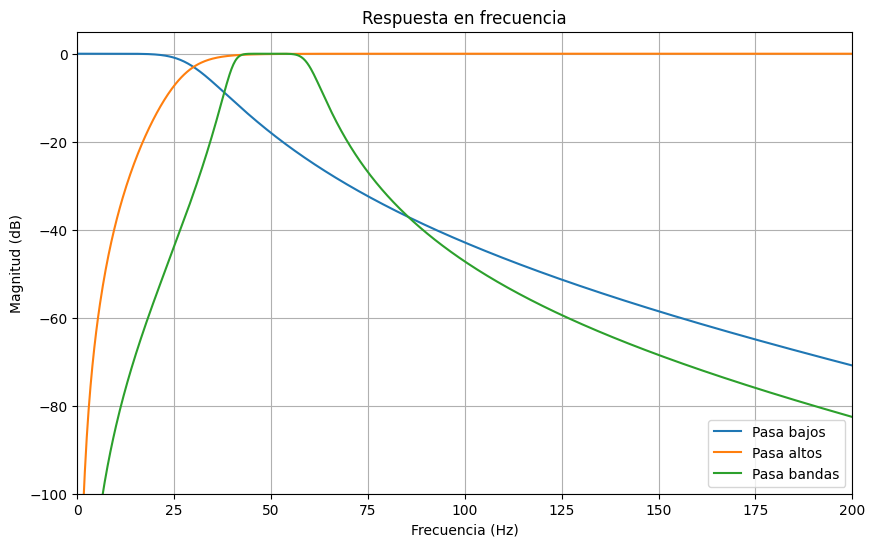

In [7]:
from scipy.signal import sosfreqz

# Calcular respuestas en frecuencia

f_lp, h_lp = sosfreqz(
    filtro_bajos, worN=2048, fs=fs
)

f_hp, h_hp = sosfreqz(
    filtro_altos, worN=2048, fs=fs
)

f_bp, h_bp = sosfreqz(
    filtro_bandas, worN=2048, fs=fs
)

# Graficar respuestas

plt.figure(figsize=(10,6))

plt.plot(f_lp, 20*np.log10(np.maximum(abs(h_lp), 1e-10)),
         label="Pasa bajos")

plt.plot(f_hp, 20*np.log10(np.maximum(abs(h_hp), 1e-10)),
         label="Pasa altos")

plt.plot(f_bp, 20*np.log10(np.maximum(abs(h_bp), 1e-10)),
         label="Pasa bandas")

plt.title("Respuesta en frecuencia")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Magnitud (dB)")

plt.xlim(0,200)
plt.ylim(-100,5)

plt.legend()
plt.grid()
plt.show()